#Fraudulent Job Posting Detection
##01 - Data exploration

This notebook explores the Employment Scam Aegean Dataset to understand the structure, distributions, missing values, and text characteristics

In [46]:
!pip install ftfy

In [47]:
#requirements for the notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ftfy
import re
import html

In [48]:
#upload the fake_job_postings.csv file
from google.colab import files

uploaded = files.upload()

Saving fake_job_postings.csv to fake_job_postings (1).csv


In [49]:
#check if it read correctly, displays first few entries
df = pd.read_csv('fake_job_postings.csv')

df.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [50]:
#checks shape of the dataframe, original is (17880,18)
df.shape

(17880, 18)

In [51]:
#displays column names, data types, and non empty cell counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   department           6333 non-null   object
 4   salary_range         2868 non-null   object
 5   company_profile      14572 non-null  object
 6   description          17879 non-null  object
 7   requirements         15184 non-null  object
 8   benefits             10668 non-null  object
 9   telecommuting        17880 non-null  int64 
 10  has_company_logo     17880 non-null  int64 
 11  has_questions        17880 non-null  int64 
 12  employment_type      14409 non-null  object
 13  required_experience  10830 non-null  object
 14  required_education   9775 non-null   object
 15  industry             12977 non-null  object
 16  func

In [52]:
df.columns.tolist()

['job_id',
 'title',
 'location',
 'department',
 'salary_range',
 'company_profile',
 'description',
 'requirements',
 'benefits',
 'telecommuting',
 'has_company_logo',
 'has_questions',
 'employment_type',
 'required_experience',
 'required_education',
 'industry',
 'function',
 'fraudulent']

In [53]:
#displays the number of entries that are authentic and fraudulent
df['fraudulent'].value_counts()

,count
fraudulent,
0,17014
1,866


In [54]:
#displays the percentage of entries that are fraudulent
df['fraudulent'].value_counts(normalize=True) * 100

,proportion
fraudulent,
0,95.1566
1,4.8434


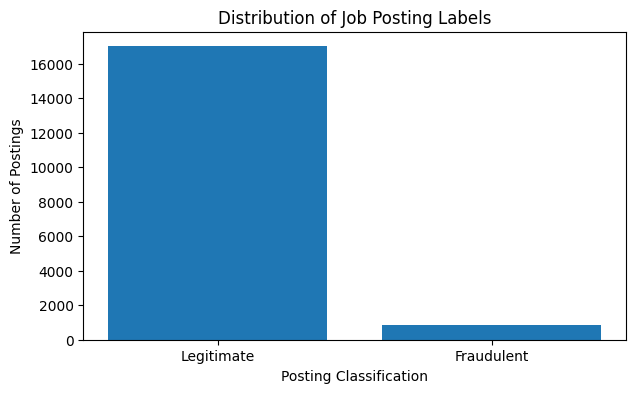

In [55]:
#charts the breakdown of fraudulent postings vs authentic
fraud_counts = df['fraudulent'].value_counts().sort_index()

plt.figure(figsize=(7, 4))

plt.bar(['Legitimate', 'Fraudulent'], fraud_counts.values)

plt.title('Distribution of Job Posting Labels')
plt.xlabel('Posting Classification')
plt.ylabel('Number of Postings')

plt.show()

In [56]:
#determines the number of values that are empty
missing_values = df.isnull().sum()

#determines the percentage of values that are empty
missing_percentages = df.isnull().mean() * 100

#displays the missing values from each column is descending order
missing_summary = pd.DataFrame({
    'Missing Count': missing_values,
    'Missing Percentage': missing_percentages
})

missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

,Missing Count,Missing Percentage
salary_range,15012,83.959732
department,11547,64.580537
required_education,8105,45.329978
benefits,7212,40.335570
required_experience,7050,39.429530
function,6455,36.101790
industry,4903,27.421700
employment_type,3471,19.412752
company_profile,3308,18.501119
requirements,2696,15.078300


In [57]:
#determines if any rows in the dataframe are identical
df.duplicated().sum()

np.int64(0)

In [58]:
#determines if any descriptions are identical for separate postings
df['description'].duplicated().sum()

np.int64(3078)

In [59]:
#determines if missing fields are more common for authentic or fraudulent postings for several different columns

#selected fields to investigate
columns_to_check = [
    'company_profile',
    'requirements',
    'benefits',
    'salary_range',
    'department'
]

#calculates missing value percentages for each class
missing_by_class = (
    df.groupby('fraudulent')[columns_to_check]
      .agg(lambda x: x.isna().mean() * 100)
      .T
)

missing_by_class.columns = ['Legitimate (%)', 'Fraudulent (%)']

print(missing_by_class.round(2))

                 Legitimate (%)  Fraudulent (%)
company_profile           15.99           67.78
requirements              14.94           17.78
benefits                  40.25           42.03
salary_range              84.45           74.25
department                64.75           61.32


In [60]:
#counts the words in each description
df['description_length'] = (
    df['description']
    .fillna('')
    .str.split()
    .str.len()
)

#compare description lengths by classification
df.groupby('fraudulent')['description_length'].describe()

,count,mean,std,min,25%,50%,75%,max
fraudulent,,,,,,,,
0,17014.0,171.041378,122.561633,1.0,88.0,147.0,225.0,2115.0
1,866.0,158.748268,136.633010,0.0,67.0,113.5,213.0,1183.0


<Figure size 900x500 with 0 Axes>

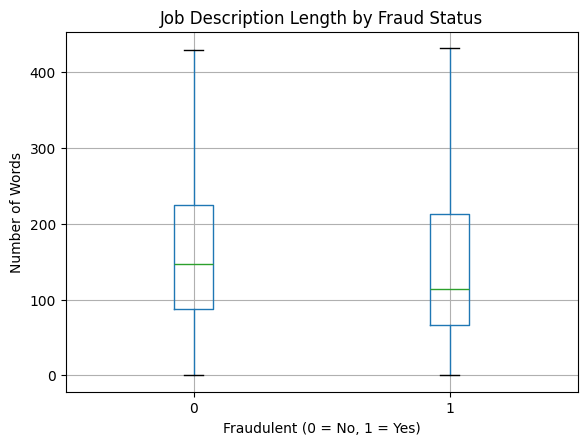

In [61]:
#chart the description length based on fraud status with box and whisker
plt.figure(figsize=(9, 5))

df.boxplot(
    column='description_length',
    by='fraudulent',
    showfliers=False
)

plt.title('Job Description Length by Fraud Status')
plt.suptitle('')
plt.xlabel('Fraudulent (0 = No, 1 = Yes)')
plt.ylabel('Number of Words')

plt.show()

In [62]:
#count exact duplicate rows
print("Duplicate rows:", df.duplicated().sum())

#count duplicate descriptions
print(
    "Duplicate descriptions:",
    df['description'].duplicated().sum()
)

Duplicate rows: 0
Duplicate descriptions: 3078


In [63]:
#displays the number of unique descriptions and the number of descriptions appearing more than once
description_counts = df['description'].value_counts()

print("Unique descriptions:", df['description'].nunique())
print("Descriptions appearing more than once:",
      (description_counts > 1).sum())

#displays the first few descriptions appearing more than once
description_counts.head(10)

Unique descriptions: 14801
Descriptions appearing more than once: 1190


,count
description,
"Play with kids, get paid for it Love travel? Jobs in Asia$1,500+ USD monthly ($200 Cost of living)Housing provided (Private/Furnished)Airfare ReimbursedExcellent for student loans/credit cardsGabriel Adkins : #URL_ed9094c60184b8a4975333957f05be37e69d3cdb68decc9dd9a4242733cfd7f7##URL_75db76d58f7994c7db24e8998c2fc953ab9a20ea9ac948b217693963f78d2e6b#12 month contract : Apply today",379
"Play with kids, get paid for it :-)Love travel? Jobs in Asia$1500 USD + monthly ($200 Cost of living)Housing providedAirfare ReimbursedExcellent for student loans/credit cardsGabriel Adkins : #URL_ed9094c60184b8a4975333957f05be37e69d3cdb68decc9dd9a4242733cfd7f7##URL_75db76d58f7994c7db24e8998c2fc953ab9a20ea9ac948b217693963f78d2e6b#",66
"Play with kids, get paid for it Love travel? Jobs in Asia$1500 USD + monthly ($200 Cost of living)Excellent for student loans/credit cardsHousing provided (Furnished/Private)Airfare ReimbursedRemind us when you wanted to start when applying :-)",46
The International Broadcaster shall properly complete all daily tasks. These daily tasks include but are not limited to: preparing for assignments (fails not more than once per week); revising video packages (fails not more than twice per week); correcting production errors in stories (fails not more than twice per week); properly creating line-ups and logs (fails not more than once per week).,33
"Play with kids, get paid for it :-)Love travel? Jobs in Asia$1500 USD + monthly ($200 Cost of living)Housing providedAirfare ReimbursedExcellent for student loans/credit cardsGabriel Adkins (#URL_ed9094c60184b8a4975333957f05be37e69d3cdb68decc9dd9a4242733cfd7f7#)#URL_75db76d58f7994c7db24e8998c2fc953ab9a20ea9ac948b217693963f78d2e6b#",32
"Play with kids, get paid for it Love travel? Jobs in Asia$1,500+ USD monthly ($200 Cost of living)Housing provided (Private/Furnished)Airfare ReimbursedExcellent for student loans/credit cardsGabriel Adkins : #URL_ed9094c60184b8a4975333957f05be37e69d3cdb68decc9dd9a4242733cfd7f7##URL_75db76d58f7994c7db24e8998c2fc953ab9a20ea9ac948b217693963f78d2e6b#12 month contract : Apply today :-)",29
"General Summary: Achieves maximum sales profitability, growth and account penetration within an assigned territory and/or market segment by effectively selling the company’s products and/or related services. Personally contacts and secures new business accounts/customers.CORE FUNCTIONS:•Promotes/sells/secures orders from existing and prospective customers through a relationship-based approach.•Demonstrates products and services to existing/potential customers and assists themin selecting those best suited to their needs.DETAILS OF FUNCTION:•Establishes, develops and maintains business relationships withcurrent customers and prospective customers in the assigned territory/market segment to generate new business for the organization’s products/services.•Makes telephone calls and in-person visits and presentations to existing and prospective customers.•Researches sources for developing prospective customers and for information to determine their potential.•Develops clear and effective written proposals/quotations for current and prospective customers.•Expedites the resolution of customer problems and complaints.•Coordinates sales effort with marketing, sales management, accounting, logistics and technical servicegroups.•Analyzes the territory/market’s potential and determines the value of existing and prospective customers value to the organization.•Creates and manages a customer value plan for existing customers highlighting profile, share and value opportunities.•Identifies advantages and compares organization’s products/services.•Plans and organizes personal sales strategy by maximizing the Return on Time Investment for the territory/segment.•Supplies management with oral and written reports on customer needs, problems, interests, competitive activities, and potential for new products and services.•Keeps abreast of product applications, technic

In [64]:
#number of distinct fraud labels associated with each description
label_counts = (
    df.dropna(subset=['description'])
      .groupby('description')['fraudulent']
      .nunique()
)

#descriptions associated with both legitimate and fraudulent labels
conflicting_descriptions = label_counts[label_counts > 1]

print(
    "Descriptions with conflicting fraud labels:",
    len(conflicting_descriptions)
)

Descriptions with conflicting fraud labels: 1


In [65]:
#find a repeated description
repeated_description = description_counts.index[0]

#display postings sharing that description
df.loc[
    df['description'] == repeated_description,
    ['job_id', 'title', 'location', 'fraudulent']
].head(10)

,job_id,title,location,fraudulent
35,36,English Teacher Abroad,"US, NY, Saint Bonaventure",0
40,41,English Teacher Abroad,"US, PA, Kutztown",0
48,49,English Teacher Abroad,"US, OH, Kent",0
62,63,English Teacher Abroad,"US, CA, Sacramento",0
80,81,English Teacher Abroad,"US, CA, Anaheim",0
89,90,English Teacher Abroad,"CA, ON, Ottawa",0
99,100,English Teacher Abroad,"US, NY, New York",0
101,102,English Teacher Abroad,"CA, MB, Winnipeg",0
119,120,English Teacher Abroad,"US, MA, Amherst",0
122,123,English Teacher Abroad,"CA, ON, Brampton",0


In [66]:
#identify the most frequently repeated description
most_common_description = df['description'].value_counts().index[0]

#find all postings with that description
repeated_postings = df[
    df['description'] == most_common_description
]

#determine the fraud labels for those postings
print(repeated_postings['fraudulent'].value_counts())

#examine titles and locations for those postings
display(
    repeated_postings[
        ['job_id', 'title', 'location', 'fraudulent']
    ].head(15)
)

fraudulent
0    379
Name: count, dtype: int64


,job_id,title,location,fraudulent
35,36,English Teacher Abroad,"US, NY, Saint Bonaventure",0
40,41,English Teacher Abroad,"US, PA, Kutztown",0
48,49,English Teacher Abroad,"US, OH, Kent",0
62,63,English Teacher Abroad,"US, CA, Sacramento",0
80,81,English Teacher Abroad,"US, CA, Anaheim",0
89,90,English Teacher Abroad,"CA, ON, Ottawa",0
99,100,English Teacher Abroad,"US, NY, New York",0
101,102,English Teacher Abroad,"CA, MB, Winnipeg",0
119,120,English Teacher Abroad,"US, MA, Amherst",0
122,123,English Teacher Abroad,"CA, ON, Brampton",0


In [67]:
#identify the description with conflicting labels
conflicting_description = conflicting_descriptions.index[0]

#find all postings with that description
conflicting_postings = df[
    df['description'] == conflicting_description
]

#display other fields from those postings
display(
    conflicting_postings[
        [
            'job_id',
            'title',
            'location',
            'company_profile',
            'has_company_logo',
            'fraudulent'
        ]
    ]
)

,job_id,title,location,company_profile,has_company_logo,fraudulent
9138,9139,Front-End/JavaScript Engineer,"ID, JW, Jakarta",NaN,0,1
11889,11890,Developer (Front-end team),"GR, I, Athens",Workable is a venture-backed startup making cl...,1,0
15236,15237,Developer,"GR, I, Athens",Workable is a venture-backed startup making cl...,1,0


#Duplicate descriptions and conflicting labels
The dataset contains 1190 unique descriptions that appear more than once. Investigation showed that a single description is associated with both legitimate and fraudulant postings.

The description appears in three postings. One located in Jakarta is labeled fraudulant while two others located in Athens are labeled authentic. The descriptions are identical but the fraudulent post lacks a company profile and a logo which are present in the authentic posts.

These details show that classification based only on descriptions may be limited. Incorporating additional information could improve accuracy.
To reduce leakage, identical descriptions will be restricted to training or testing sets, not both.

In [68]:
#function to clean text. Repairs errors that occur due to encoding conflicts, handles html issues, manually replaces some encoding errors that were not handled before, replaces URL's with a consistent label, adds spaces if missing after punctuation, colons, or between words
def repair_text(text):
    if not isinstance(text, str):
        return ""

    #1. repair common encoding problems
    text = ftfy.fix_text(text)

    #2. decode HTML issues
    text = html.unescape(text)

    #3. fix remaining known encoding errors
    encoding_fixes = {
        'â€“': '–',
        'â€”': '—',
        'â€¦': '…',
        'â€™': "'",
        'â€œ': '"',
        'â€\x9d': '"'
    }

    for incorrect, correct in encoding_fixes.items():
        text = text.replace(incorrect, correct)

    #4. replace dataset URL placeholders with consistent label
    text = re.sub(
        r'#URL_[a-fA-F0-9]+#',
        ' URLTOKEN ',
        text
    )

    #5. add missing spaces after punctuation
    text = re.sub(
        r'([.!?])(?=[A-Za-z])',
        r'\1 ',
        text
    )

    #6. add missing spaces after colons
    text = re.sub(
        r':(?=[A-Za-z])',
        ': ',
        text
    )

    #7. separate joined lowercase and uppercase words
    text = re.sub(
        r'([a-z])([A-Z])',
        r'\1 \2',
        text
    )

    #8. normalize whitespace
    text = re.sub(r'\s+', ' ', text)

    return text.strip()

In [69]:
#tests repair function with a single entry, displays the original and cleaned version
original = df.loc[3, 'description']

cleaned = repair_text(original)

print("ORIGINAL:\n")
print(original[:1000])

print("\nCLEANED:\n")
print(cleaned[:1000])

ORIGINAL:

THE COMPANY: ESRI – Environmental Systems Research InstituteOur passion for improving quality of life through geography is at the heart of everything we do.  Esri’s geographic information system (GIS) technology inspires and enables governments, universities and businesses worldwide to save money, lives and our environment through a deeper understanding of the changing world around them.Carefully managed growth and zero debt give Esri stability that is uncommon in today's volatile business world.  Privately held, we offer exceptional benefits, competitive salaries, 401(k) and profit-sharing programs, opportunities for personal and professional growth, and much more.THE OPPORTUNITY: Account ExecutiveAs a member of the Sales Division, you will work collaboratively with an account team in order to sell and promote adoption of Esri’s ArcGIS platform within an organization. As part of an account team, you will be responsible for facilitating the development and execution of a set

In [70]:
#performs cleaning on the selected columns
text_columns = [
    'description',
    'company_profile',
    'requirements',
    'benefits'
]

#adds a new column for the cleaned version of each selected column
#description_repaired is a new column name for example
for col in text_columns:
    df[col + '_repaired'] = df[col].apply(repair_text)

In [71]:
#displays the number of unique descriptions before and after cleaning
print(
    "Unique original descriptions:",
    df['description'].nunique()
)

print(
    "Unique repaired descriptions:",
    df['description_repaired'].nunique()
)

Unique original descriptions: 14801
Unique repaired descriptions: 14516


In [72]:
#determines if the repeated description with both the authentic and fraudulent class is still present after cleaning
label_counts = (
    df.groupby('description_repaired')['fraudulent']
      .nunique()
)

conflicting_repaired = label_counts[label_counts > 1]

print(
    "Repaired descriptions with conflicting labels:",
    len(conflicting_repaired)
)

Repaired descriptions with conflicting labels: 1


In [44]:
#exports the modified dataset
df.to_csv('fake_job_postings_cleaned.csv', index=False)

In [45]:
#downloads the csv with the cleaned columns
from google.colab import files

files.download('fake_job_postings_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [73]:
#calculates word counts for repaired descriptions
df['description_length_repaired'] = (
    df['description_repaired']
    .fillna('')
    .str.split()
    .str.len()
)

#compares original and repaired description lengths to see if the cleaned lengths are noticeably different for authentic and fraudulent
comparison = df.groupby('fraudulent')[
    ['description_length', 'description_length_repaired']
].agg(['mean', 'median'])

comparison.round(2)

description_length        description_length_repaired       
                         mean median                        mean median
fraudulent                                                             
0                      171.04  147.0                      178.25  154.0
1                      158.75  113.5                      164.41  120.0

#Text cleaning
The dataset contained several text quality issues such as encoding errors, inconsistent whitespace, missing word separations, and URL's.

A cleaning function using ftfy, HTML decoding, and regular expressions was created. The URL's were standardized to retain the fact that a URL was present without the random string of characters impacting the classification.

The original text columns were kept intact and the cleaned columns were joined. After cleaning, the unique job descriptions dropped from 14,801 to 14,516 which shows that some descriptions only differed in formatting or other inconsistency. A small number of encoding errors are still present but the repaired text is clean enough for further analysis.

The repaired text will be used for feature extraction and classification.